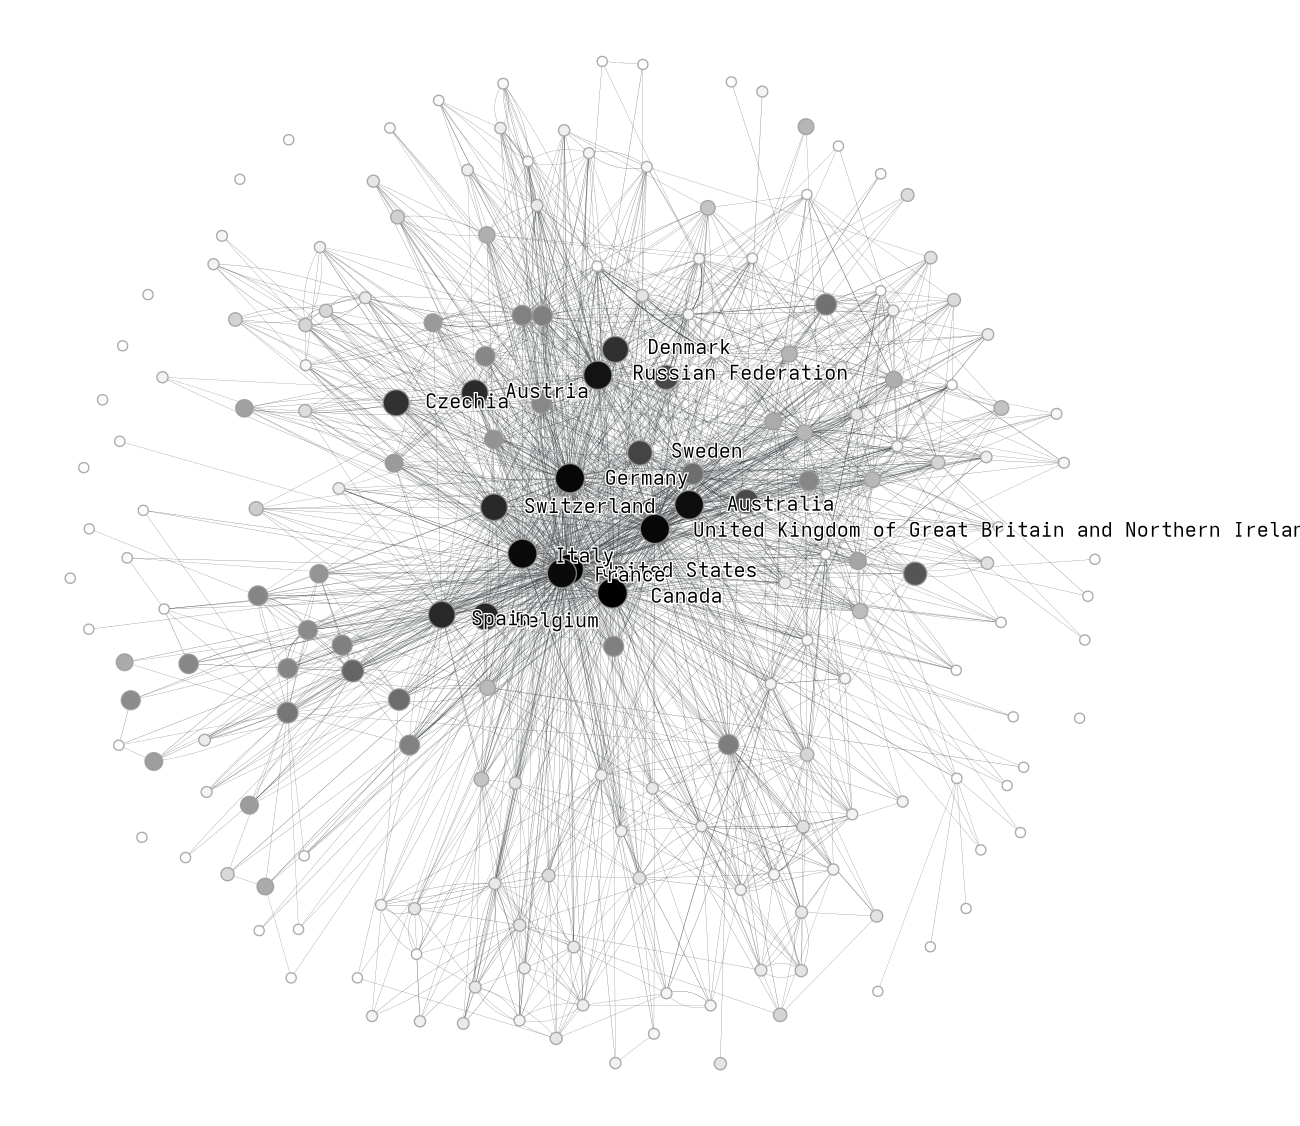

<VertexPropertyMap object with value type 'vector<double>', for Graph 0x7fd253b22f30, at 0x7fd2044a1550>

In [62]:
import numpy as np
import graph_tool.all as gt
import graph_tool.draw

# ====== Готовим смещение текста для топ-15 вершин ======
vertex_text_offset = g_view.new_vertex_property("vector<double>")
vertex_vorder = g.new_vertex_property("int")

# Центр графа
cx = np.mean([pos[v][0] for v in g_view.vertices()])
cy = np.mean([pos[v][1] for v in g_view.vertices()])

# Размах координат для масштабирования
xs = [pos[v][0] for v in g_view.vertices()]
ys = [pos[v][1] for v in g_view.vertices()]
scale = 0.003 * max(np.ptp(xs), np.ptp(ys))   # можно увеличить до 0.3–0.4 при сильных наложениях

for v in g_view.vertices():
    if vertex_text[v] != "":   # только для вершин с подписями
        dx = pos[v][0] - cx
        dy = pos[v][1] - cy
        vertex_vorder[v] = 100 - dx
        norm = np.hypot(dx, dy) + 1e-9
        # Смещаем от центра наружу
        offset_x = (dx / norm) * scale
        offset_y = (dy / norm) * scale
        # (Опционально) добавим лёгкий случайный доворот, чтобы развести метки
        angle = np.random.uniform(-0.3, 0.3)
        # offset_x, offset_y = offset_x * np.cos(angle) - offset_y * np.sin(angle), ...
        vertex_text_offset[v] = [offset_x, offset_y]
    else:
        vertex_text_offset[v] = [0.0, 0.0]
        vertex_vorder[v] = 0

# ====== Визуализация с улучшенными настройками ======
gt.graph_draw(
    g_view,
    pos=pos,
    vertex_size=vertex_size,
    vertex_fill_color=v_color,
    edge_pen_width=edge_pen,
    vorder=vertex_vorder,
    vertex_text=vertex_text,
    vertex_font_size=10,
    vertex_text_position=0,                     # строго центр вершины
    vertex_text_alignment="center",             # центрируем сам текст относительно точки (pos+offset)
    vertex_text_color="black",
    vertex_text_offset=vertex_text_offset,      # индивидуальное смещение
    vertex_text_out_width=0.05,
    vertex_text_out_color='white',
    output_size=(650, 650)
)

In [13]:
import graph_tool.all as gt
import numpy as np
import logging
import pandas as pd

In [14]:
g = gt.Graph()
g.load(file_name = 'graphml/n_human_2008.lxml', fmt = 'xml')

In [64]:
def countCentrality(G, country_list: list, centrality_type: str, prefix: str = ""):
    """A function to measure centrality in a network
    
    Parameters
    ------------
        G: networkx.Graph or networkx.DiGraph
            Network graph
        country_list: list
            List of all countries (or other agents) in the network
        centrality_type: str
            Method of centrality measurement (currently supports out-degree centrality and betweenness centrality)
        prefix: str
            Prefix to put in centrality, rank and status column names in the returned df. Default: empty string.
    Return
    -----------
        centrality_df : pd.DataFrame()
            DataFrame containing information about centrality, rank and status of all nodes in the network. 
    
    """
    if centrality_type == 'out-degree':
        centrality = nx.out_degree_centrality(G)
    elif centrality_type == 'out-degree-weighted':
        logging.info("analysing out-degree-weighted centrality")
    #    out_degree_centrality = {node: sum(weight for _, _, weight in G.out_edges(node, data='value')) for node in G.nodes()}
        centrality = {}
        for node in G.vertices():
            #return G, node
            out_strength = sum(g.edge_properties["weight"].a[neighbor] for neighbor in G.get_out_neighbors(node))
            centrality[node] = out_strength
    elif centrality_type == 'betweenness':
        centrality = gt.centrality.betweenness(G, weight='value', norm=True)
#nx.betweenness_centrality(G)#, weight='value')
    elif centrality_type == 'laplacian':
        centrality = nx.laplacian_centrality(G, weight='value')
    elif centrality_type == 'pagerank':
        centrality = nx.pagerank(G.reverse(), weight='value')
    else:
        raise NotImplementedError(centrality_type)
    
    
    #centrality_df = pd.DataFrame()
    
    ##if prefix != "":
    # #   prefix = prefix + "_"
    #for country in country_list:
    #    centrality_df.loc[country, f'{prefix}centrality'] = centrality[country]
    #centrality_df[f'{prefix}rank'] = centrality_df.rank(ascending=False)
    #centrality_df[f'{prefix}status'] = len(country_list) / centrality_df[f'{prefix}rank']
    return centrality

In [65]:
weights = g.edge_properties["weight"].a   # массив numpy со значениями
threshold = np.percentile(weights[weights > 0], 75)   # игнорируем нулевые веса, если есть

# Создаём булев фильтр: True для рёбер, чей вес >= порога
edge_filter = g.new_edge_property("bool")
for e in g.edges():
    edge_filter[e] = g.edge_properties["weight"][e] >= threshold

# Конструируем представление
g_view = gt.GraphView(g, efilt=edge_filter)


In [66]:
centrality_list = countCentrality(g, country_list=list(g.vertex_properties["_graphml_vertex_id"]), centrality_type='out-degree-weighted')

vertex_centrality = g.new_vertex_property("float")

for e in g.vertices():
    vertex_centrality[e] = float(centrality_list[e])

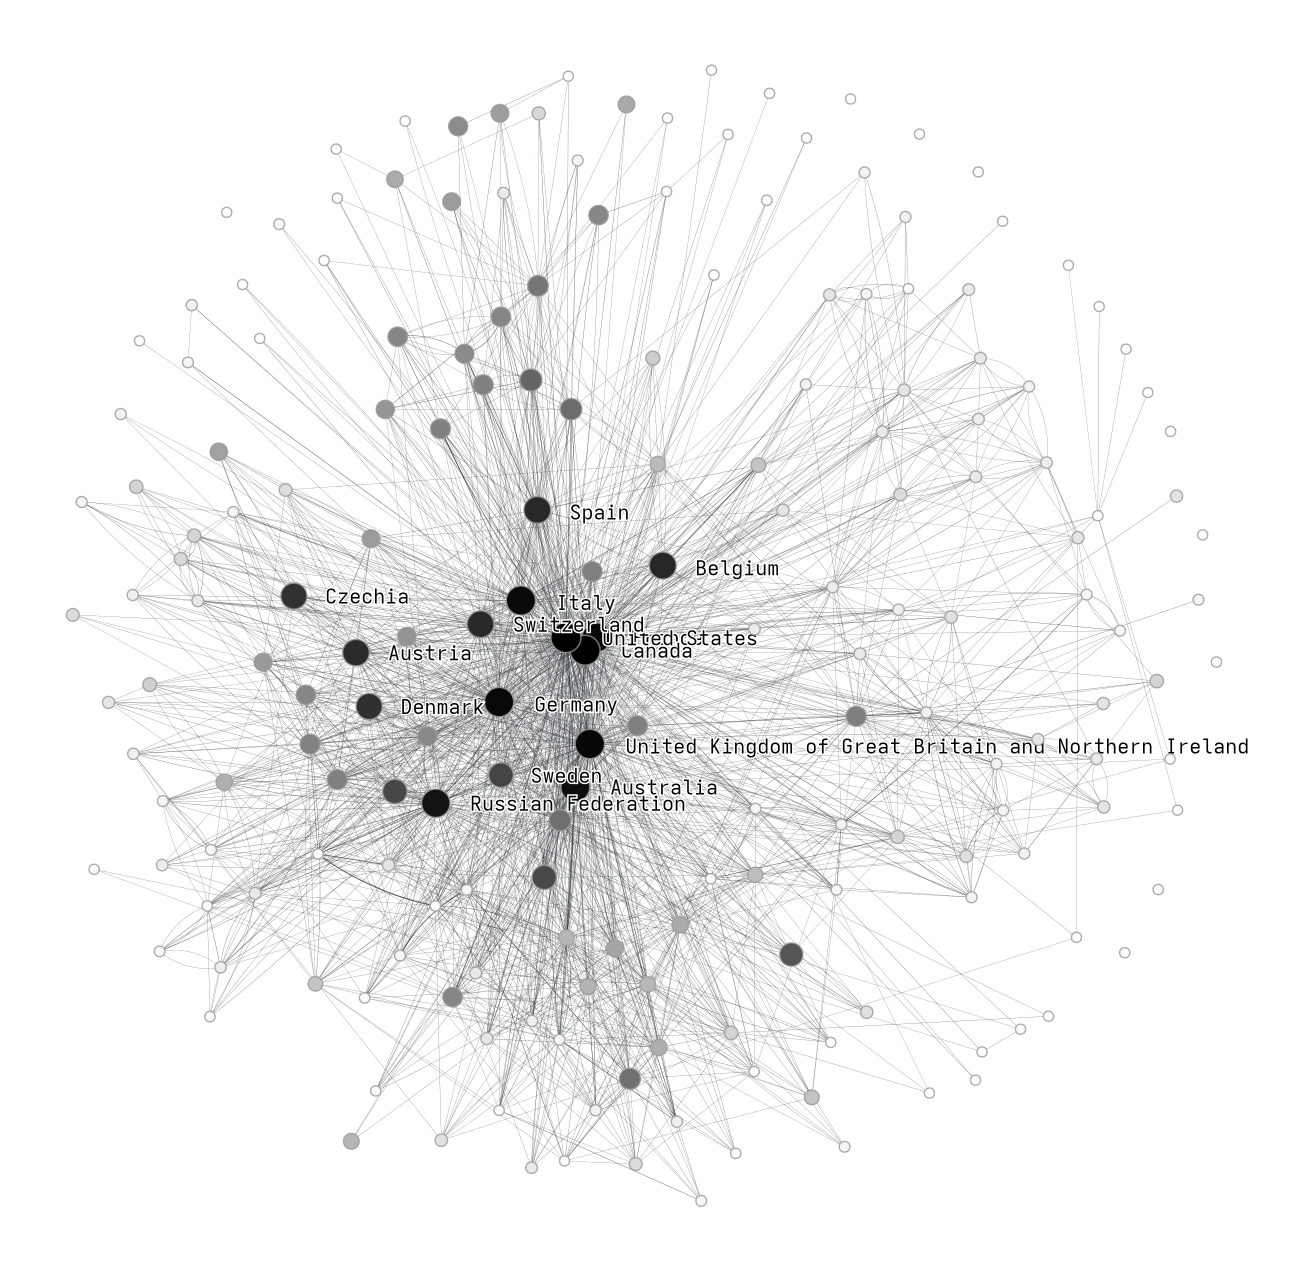

<VertexPropertyMap object with value type 'vector<double>', for Graph 0x7fd20899aad0, at 0x7fd2095248a0>

In [67]:
# 1. Центральность считаем на ПОЛНОМ графе g
#centrality = gt.pagerank(g, weight=g.edge_properties["weight"])
centrality = vertex_centrality

# 2. Готовим визуальные свойства для g_view
# Создаём карты свойств непосредственно на g_view
vertex_size = g_view.new_vertex_property("float")
v_color = g_view.new_vertex_property("vector<double>")
vertex_vorder = g.new_vertex_property("int")

c_min, c_max = centrality.a.min(), centrality.a.max()

#pos = gt.sfdp_layout(g_view)
pos = gt.arf_layout(g_view, a=3, d=1.7, max_iter=10000)

for v in g_view.vertices():   # итерируем по вершинам представления
    # размер на основе центральности
    vertex_size[v] = 5 + 10 * (centrality[v] - c_min) / (c_max - c_min) if c_max > c_min else 15
    
    t = (centrality[v] - c_min) / (c_max - c_min) if c_max > c_min else 0.5
    # цвет от синего к красному
    #v_color[v] = [t, 0.2, 1.0 - t, 1.0]
    v_color[v] = [1 - t, 1 - t, 1 - t, 1.0]
    vertex_vorder[v] = (1/pos[v][0])*10000#centrality[v]*100

# Толщина рёбер тоже берётся из g_view (оно унаследует свойство "weight")
edge_pen = gt.prop_to_size(g_view.edge_properties["weight"], mi=0.1, ma=0.5)

# 1. Определяем топ-15 вершин по центральности
sorted_indices = np.argsort(centrality.a)[::-1][:15]
top_set = set(sorted_indices)  # множество индексов для быстрой проверки


# 2. Получаем свойство с идентификаторами из полного графа
node_id_prop = g.vertex_properties["_graphml_vertex_id"]   # или другое имя свойства

# 3. Создаём текстовую карту для GraphView
vertex_text = g_view.new_vertex_property("string")

for v in g_view.vertices():
    idx = int(v)
    if idx in top_set:
        vertex_text[v] = str(node_id_prop[v])  # берем ID из оригинального графа
    else:
        vertex_text[v] = ""

# 4. Визуализация
gt.graph_draw(
    g_view,
    pos=pos,
    vertex_size=vertex_size,
    vertex_fill_color=v_color,
    edge_pen_width=edge_pen,
    vorder=vertex_vorder,
    vertex_text=vertex_text,
    vertex_font_size=10,
    vertex_text_position=0.001,
    vertex_text_color = "black",
    vertex_text_offset = [0.0, 0.0],
    vertex_text_out_width=0.05,
    vertex_text_out_color='white',
    output_size=(650, 650)
#    vprops={"font_size": 10, "font_color": [1,1,1,1], "font_outline": True},

#    output="graph_with_ids.pdf"
)

In [7]:
gt.Gtk.init_check()

AttributeError: module 'graph_tool.all' has no attribute 'Gtk'

In [8]:
from math import sqrt

In [9]:
g = gt.price_network(1500)
deg = g.degree_property_map("in")
deg.a = 2 * (sqrt(1) * 0.5 + 0.4)
ebet = gt.betweenness(g)[1]
gt.graphviz_draw(g, vcolor=deg, vorder=deg, elen=10,
                 ecolor=ebet, eorder=ebet, output="graphviz-draw.pdf")

NameError: name 'libgv' is not defined

In [10]:

# ------------------ 3. Визуализация ------------------
pos = gt.sfdp_layout(g_view)   # или radial_tree_layout, fruchterman_reingold и т.д.

# Размер вершин – по центральности
vertex_size = gt.prop_to_size(centrality, mi=5, ma=30)

# Цвет вершин – градиент от холодного к тёплому по центральности
v_color = g.new_vertex_property("vector<double>")
c_min, c_max = centrality.a.min(), centrality.a.max()
for v in g.vertices():
    t = (centrality[v] - c_min) / (c_max - c_min) if c_max > c_min else 0.5
    v_color[v] = [t, 0.2, 1.0 - t, 1.0]   # RGBA, от синего (0) до красного (1)

# Толщина рёбер – пропорционально весу (работает и на view, т.к. свойство унаследовано)
edge_pen = gt.prop_to_size(g.edge_properties["weight"], mi=0.5, ma=3.0)

gt.graph_draw(
    g_view,
    pos=pos,
    vertex_size=vertex_size,
    vertex_fill_color=v_color,
    edge_pen_width=edge_pen,
    output_size=(1200, 1200),
    #output="strong_ties.pdf"
)


KeyError: ('e', 'weight')

In [11]:
pos = gt.fruchterman_reingold_layout(g)
centrality = gt.pagerank(g, weight=g.edge_properties["weight"])

# 1. Определяем порог (например, 80-й процентиль весов)
threshold = np.percentile(weight.a, 80)

# 2. Создаем булеву карту свойств для фильтра
edge_filter = g.new_edge_property("bool")
for e in g.edges():
    print(e)
    edge_filter[e] = e >= threshold

# 3. Создаем GraphView, который будет показывать только сильные связи
g_view = gt.GraphView(g, efilt=edge_filter)

gt.graph_draw(g, pos=pos)

KeyError: ('e', 'weight')

In [12]:
# g — ваш полный граф с ребёрным свойством "weight"
# g_view — GraphView с фильтром efilt

# 1. Центральность считаем на ПОЛНОМ графе g
centrality = gt.pagerank(g, weight=g.edge_properties["weight"])

# 2. Готовим визуальные свойства для g_view
# Создаём карты свойств непосредственно на g_view
vertex_size = g_view.new_vertex_property("float")
v_color = g_view.new_vertex_property("vector<double>")

c_min, c_max = centrality.a.min(), centrality.a.max()
for v in g_view.vertices():   # итерируем по вершинам представления
    # размер на основе центральности
    vertex_size[v] = 5 + 25 * (centrality[v] - c_min) / (c_max - c_min) if c_max > c_min else 15
    # цвет от синего к красному
    t = (centrality[v] - c_min) / (c_max - c_min) if c_max > c_min else 0.5
    v_color[v] = [t, 0.2, 1.0 - t, 1.0]

# Толщина рёбер тоже берётся из g_view (оно унаследует свойство "weight")
edge_pen = gt.prop_to_size(g_view.edge_properties["weight"], mi=0.5, ma=3.0)

pos = gt.sfdp_layout(g_view)

# 3. Рисуем представление, передавая ему его собственные карты свойств
gt.graph_draw(
    g_view,
    pos=pos,
    vertex_size=vertex_size,
    vertex_fill_color=v_color,
    edge_pen_width=edge_pen,
    output_size=(1000, 1000),
#    output="graph_strong_ties_corrected.pdf"
)


KeyError: ('e', 'weight')

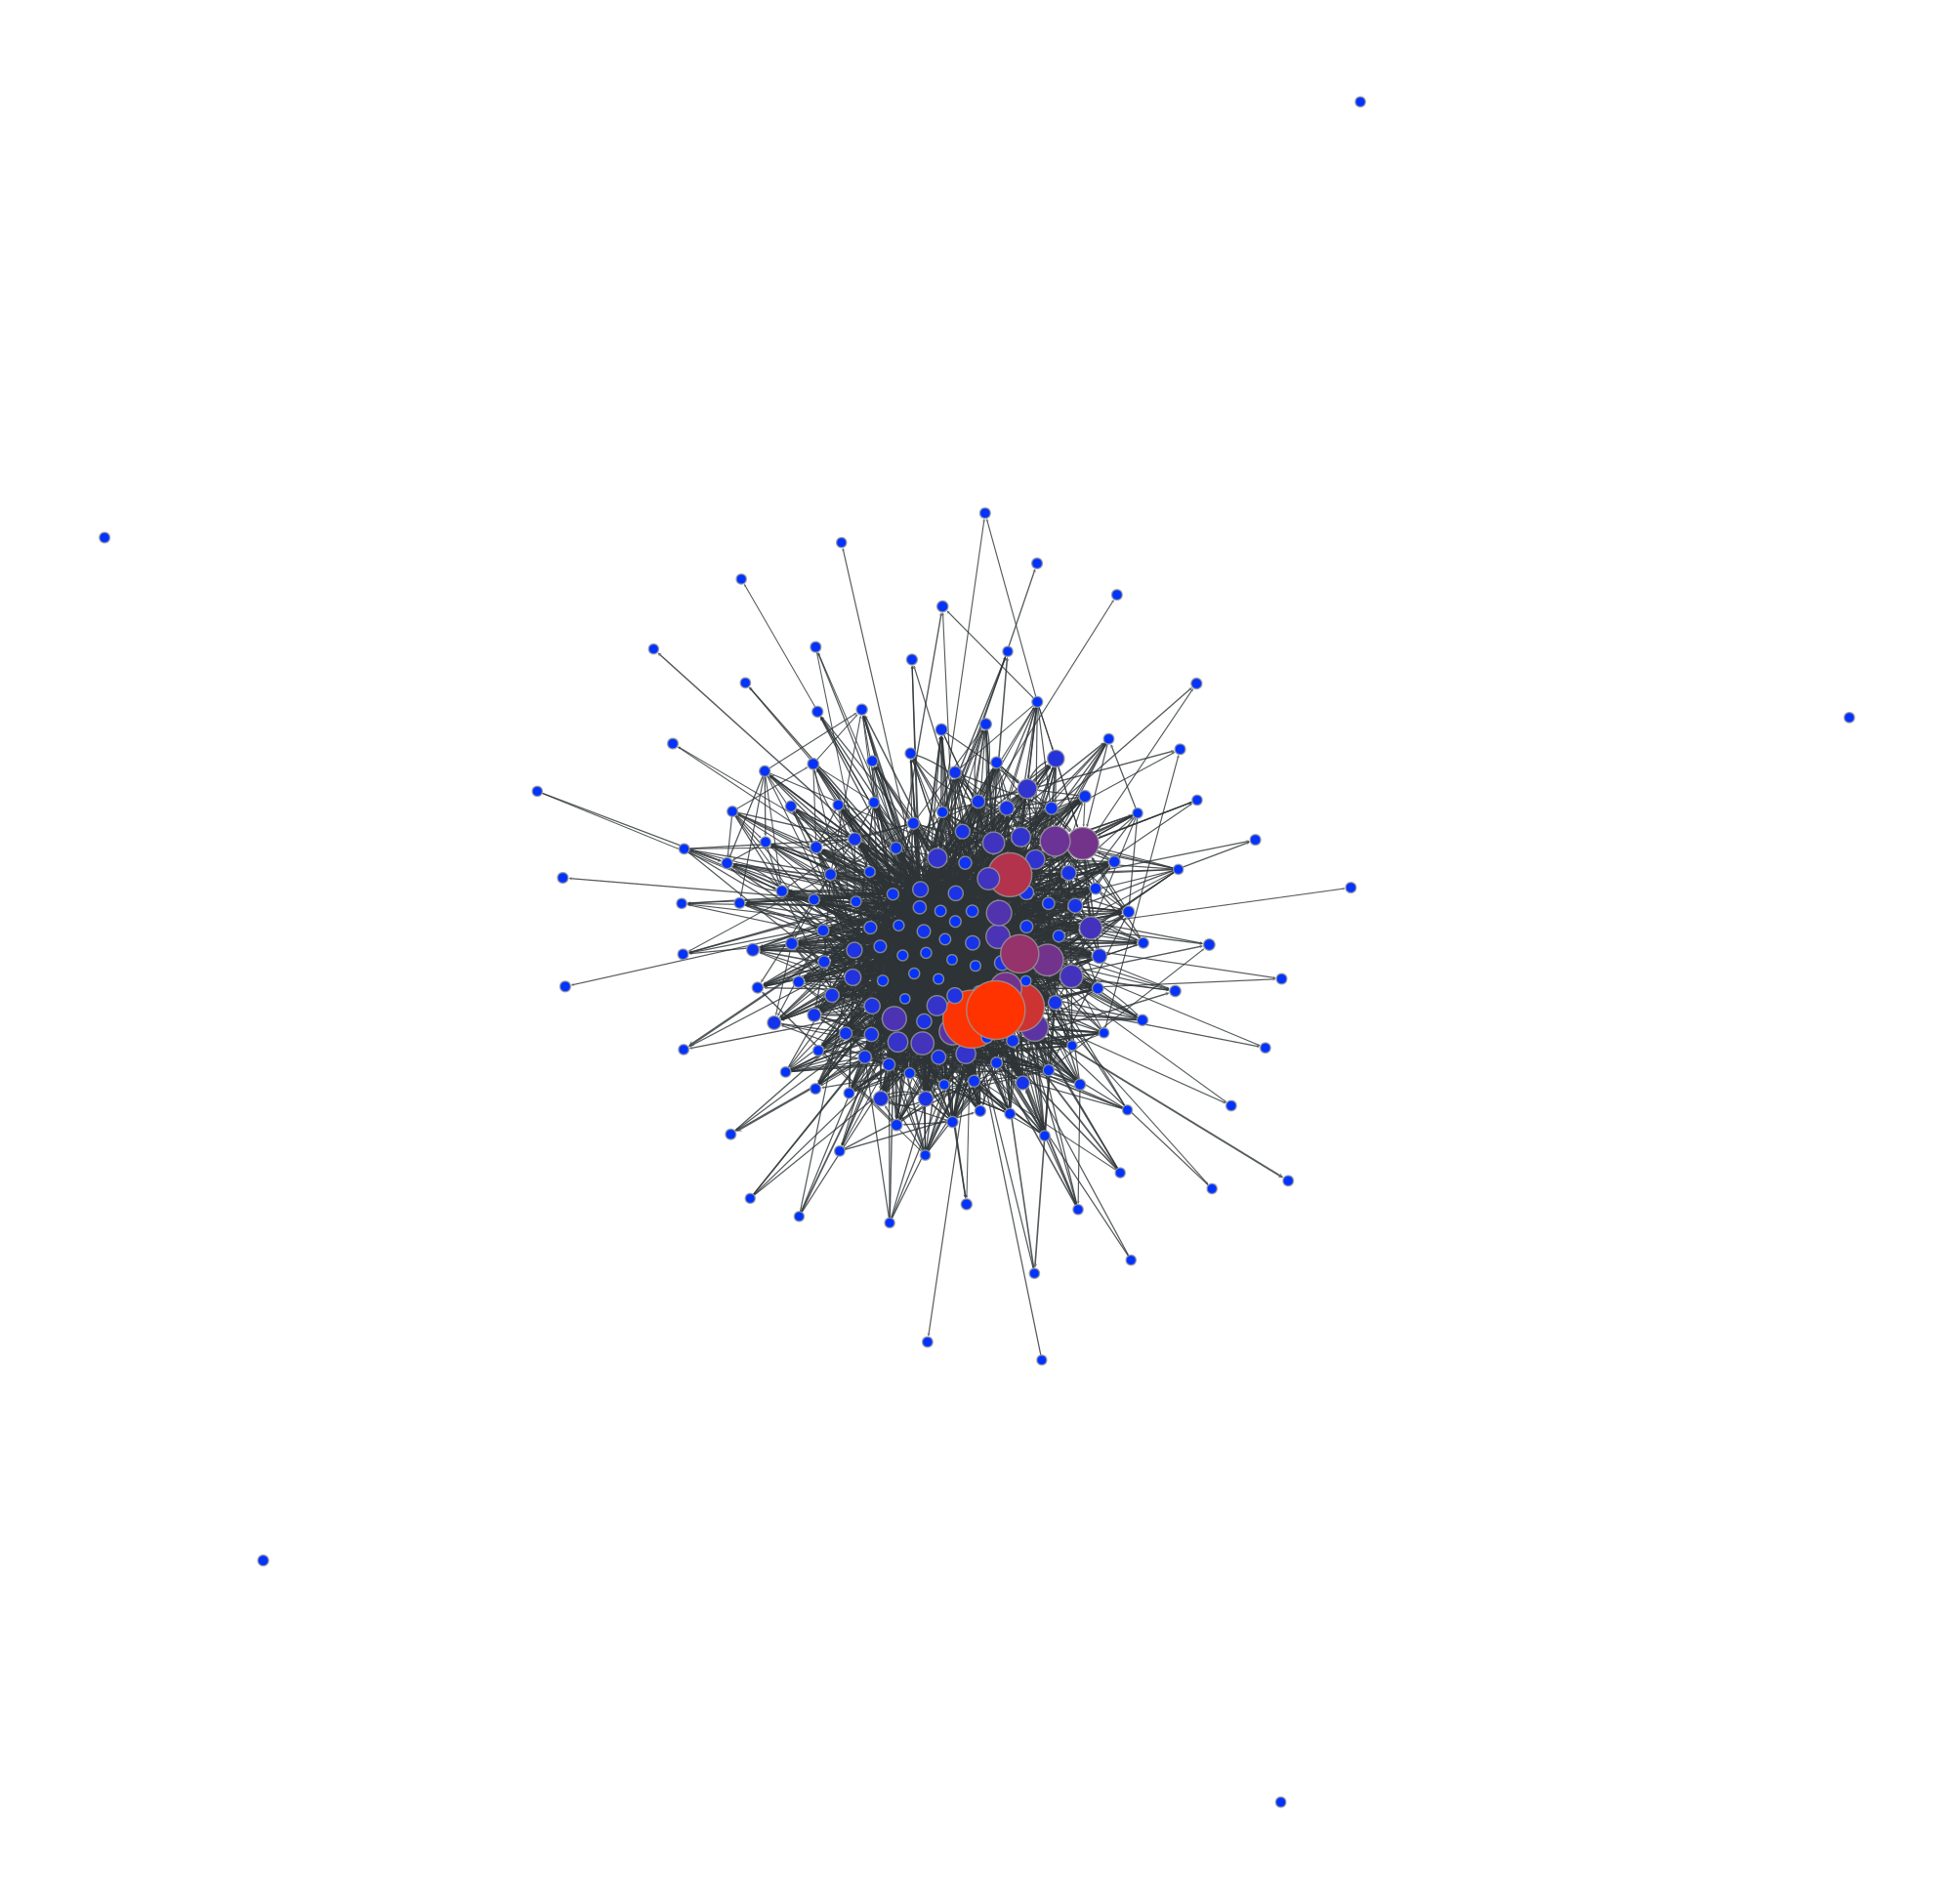

<VertexPropertyMap object with value type 'vector<double>', for Graph 0x7f6b0aaca510, at 0x7f6b0ac75940>

In [10]:
# g — ваш полный граф с ребёрным свойством "weight"
# g_view — GraphView с фильтром efilt

# 1. Центральность считаем на ПОЛНОМ графе g
centrality = gt.pagerank(g, weight=g.edge_properties["weight"])

# 2. Готовим визуальные свойства для g_view
# Создаём карты свойств непосредственно на g_view
vertex_size = g_view.new_vertex_property("float")
v_color = g_view.new_vertex_property("vector<double>")

c_min, c_max = centrality.a.min(), centrality.a.max()
for v in g_view.vertices():   # итерируем по вершинам представления
    # размер на основе центральности
    vertex_size[v] = 5 + 25 * (centrality[v] - c_min) / (c_max - c_min) if c_max > c_min else 15
    # цвет от синего к красному
    t = (centrality[v] - c_min) / (c_max - c_min) if c_max > c_min else 0.5
    v_color[v] = [t, 0.2, 1.0 - t, 1.0]

# Толщина рёбер тоже берётся из g_view (оно унаследует свойство "weight")
edge_pen = gt.prop_to_size(g_view.edge_properties["weight"], mi=0.5, ma=3.0)

pos = gt.sfdp_layout(g_view)

# 3. Рисуем представление, передавая ему его собственные карты свойств
gt.graph_draw(
    g_view,
    pos=pos,
    vertex_size=vertex_size,
    vertex_fill_color=v_color,
    edge_pen_width=edge_pen,
    output_size=(1000, 1000),
#    output="graph_strong_ties_corrected.pdf"
)


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192


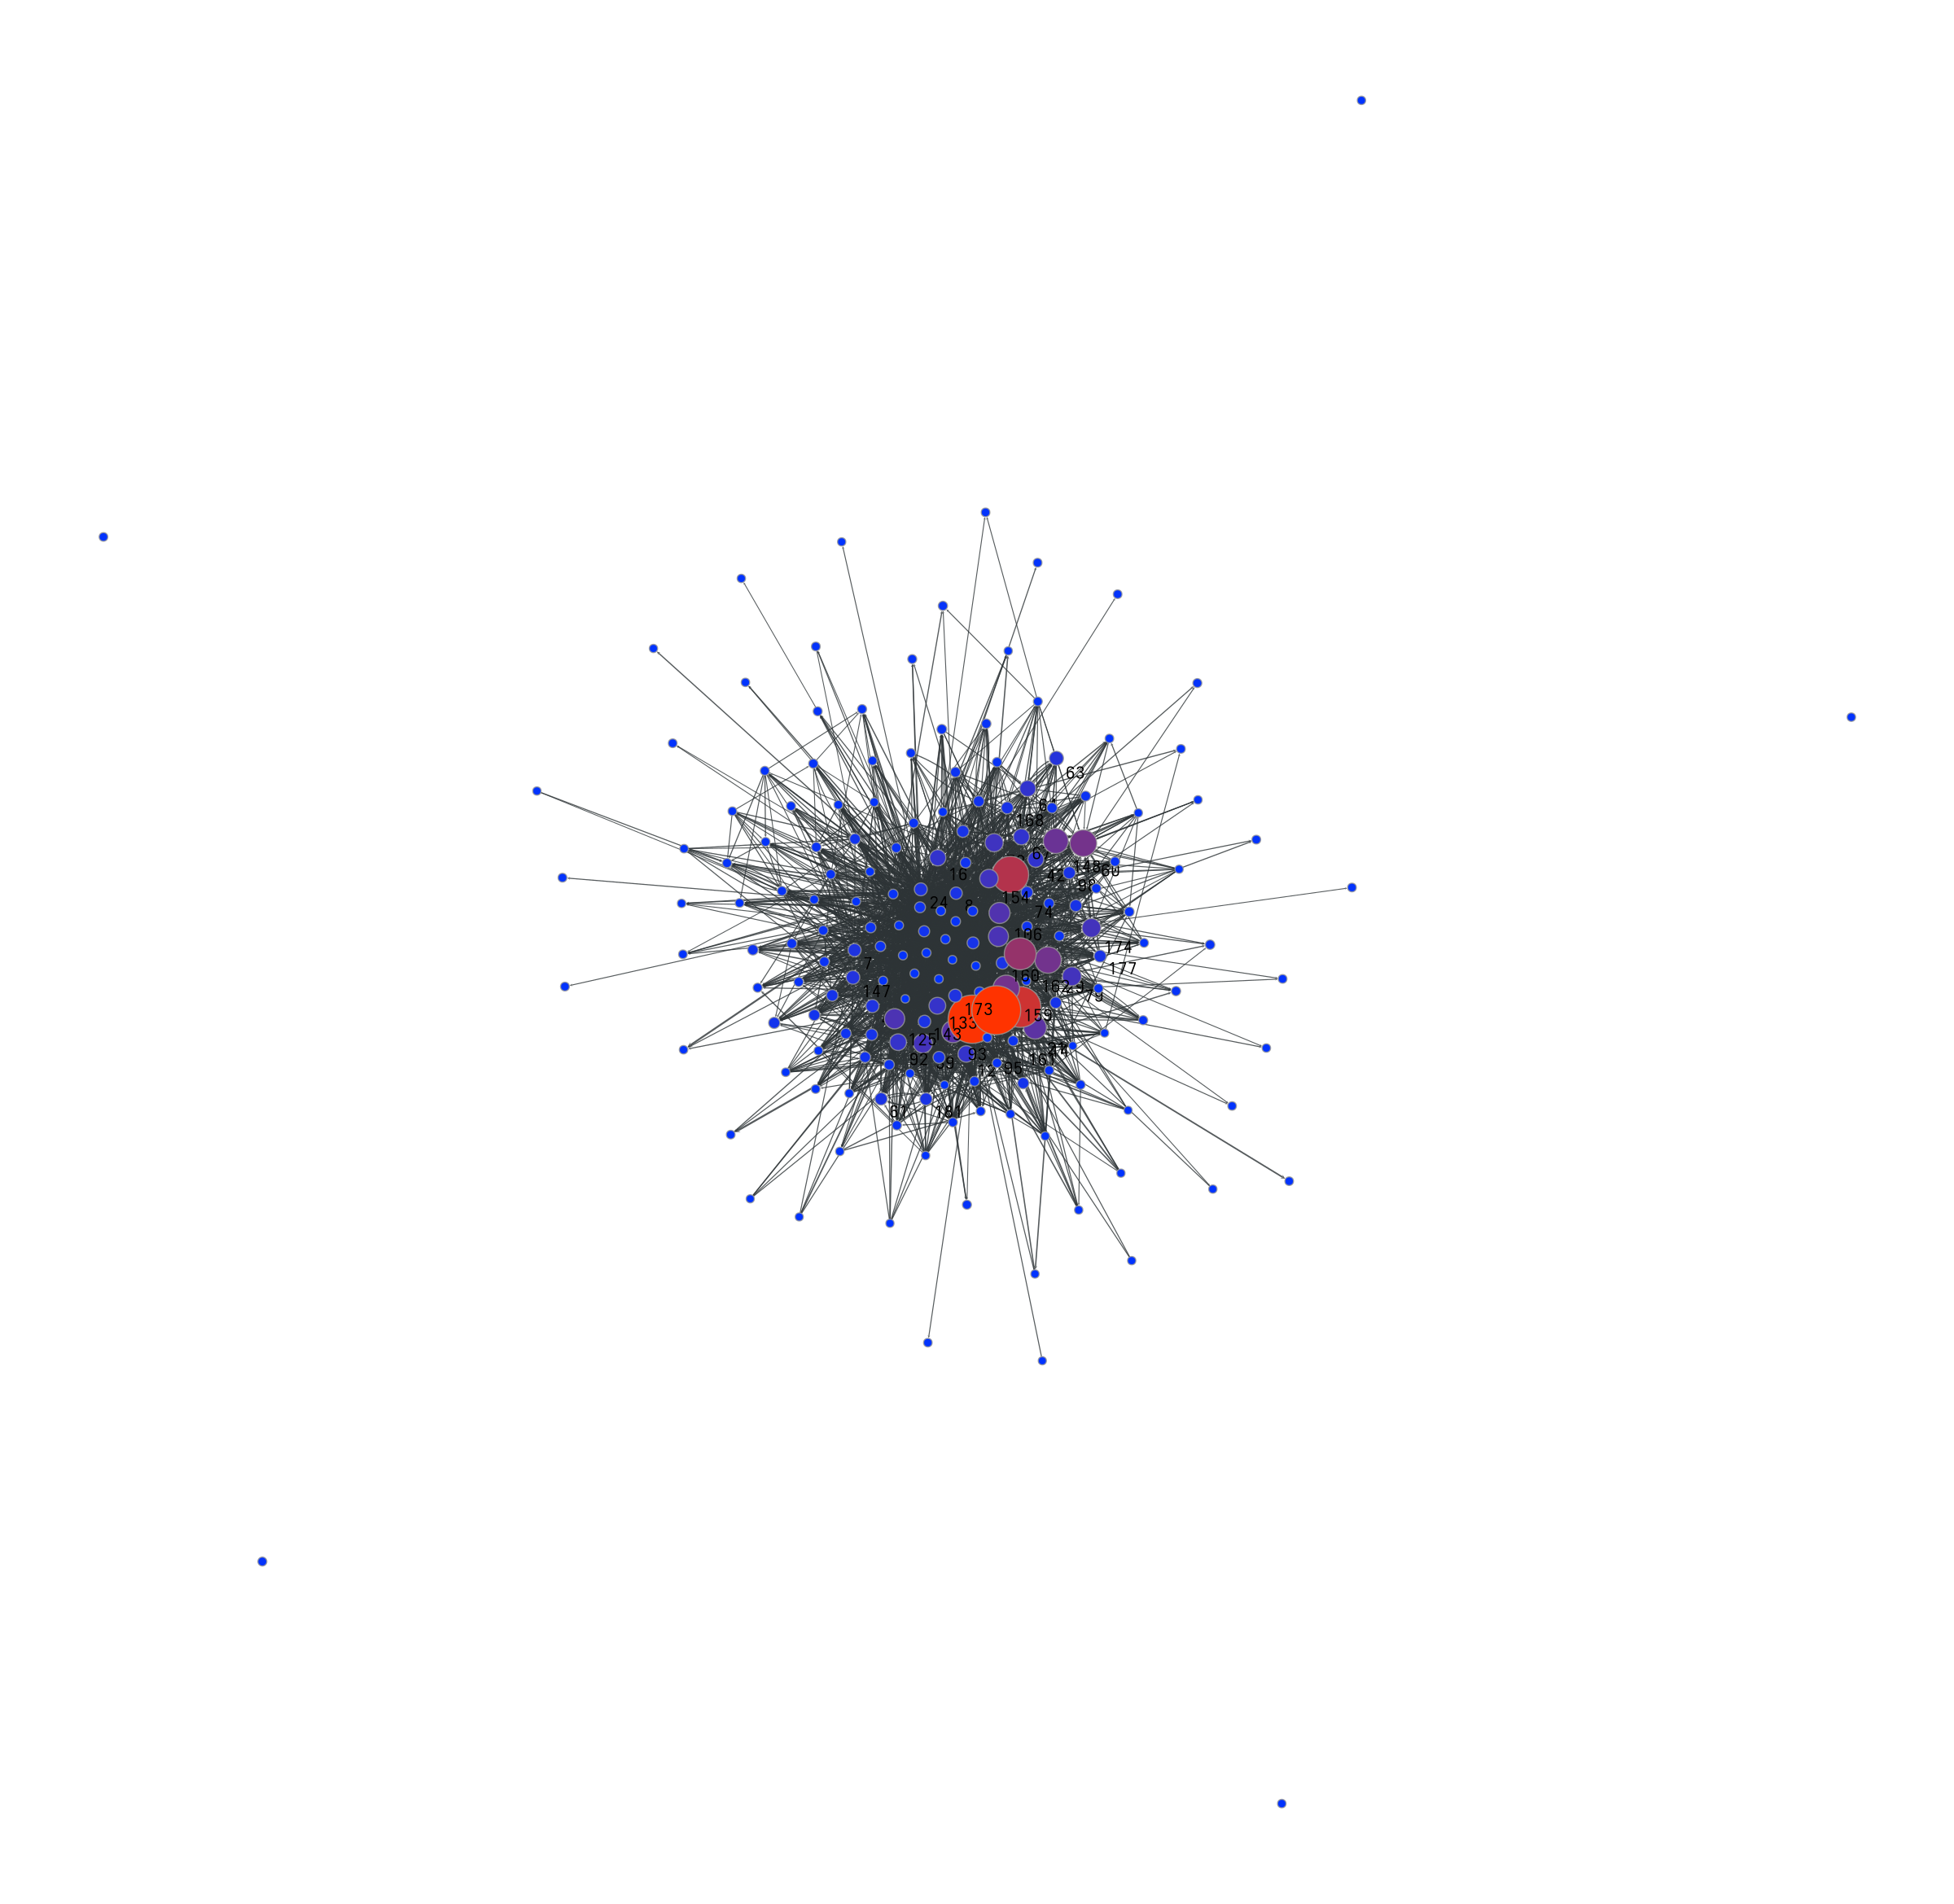

<VertexPropertyMap object with value type 'vector<double>', for Graph 0x7f6b0aaca510, at 0x7f6b0ac75b70>

In [11]:
#    centrality — PropertyMap, полученный на полном графе g
cent_array = centrality.a
# индексы вершин (в порядке возрастания центральности)
sorted_indices = np.argsort(cent_array)[::-1]  # от большего к меньшему
top40_indices = sorted_indices[:40]

# 2. Создаём карту текста для представления g_view
vertex_text = g_view.new_vertex_property("string")

# 3. Заполняем: для топ-40 ставим метку, для остальных — пустую строку
for v in g_view.vertices():
    print(v)
    idx = int(v)  # числовой индекс вершины
    if idx in top40_indices:
        # Если у вас есть свойство с именем (например, "name"), используйте его:
        # vertex_text[v] = g.vertex_properties["name"][v]
        # Иначе можно подписать просто индексом:
        vertex_text[v] = str(idx)
    else:
        vertex_text[v] = ""

# 4. Рисуем с подписями
gt.graph_draw(
    g_view,
    pos=pos,
    vertex_size=vertex_size,
    vertex_fill_color=v_color,
    edge_pen_width=edge_pen,
    vertex_text=vertex_text,            # передаём карту с метками
    vertex_font_size=10,                # размер шрифта
    vertex_text_position=1,             # 0 — по центру, 1 — снаружи вершины
    #vertex_text_offset=4,               # отступ от границы вершины (в пикселях)
    output_size=(1200, 1200),
    #output="graph_with_labels.pdf"
)